In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import html
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud, STOPWORDS

DATA_PATH = "/content/drive/MyDrive/NLP project/Combined Data.csv"
SPLIT_DIR = "/content/drive/MyDrive/NLP project"

df = pd.read_csv(DATA_PATH)
df = df.rename(columns={"Unnamed: 0": "id"})
df.head()

,id,statement,status
0,0,oh my gosh,Anxiety
1,1,"trouble sleeping, confused mind, restless heart. All out of tune",Anxiety
2,2,"All wrong, back off dear, forward doubt. Stay in a restless and restless place",Anxiety
3,3,I've shifted my focus to something else but I'm still worried,Anxiety
4,4,"I'm restless and restless, it's been a month now, boy. What do you mean?",Anxiety


In [ ]:
df = df.dropna(subset=["statement", "status"])
df["statement"] = df["statement"].map(html.unescape)
df["statement"] = df["statement"].str.replace(r"\s+", " ", regex=True).str.strip()
df = df[df["statement"] != ""]

# drop texts that appear with different labels, then duplicates (case-insensitive)
key = df["statement"].str.lower()
df = df[df.groupby(key)["status"].transform("nunique") == 1]
df = df[~df["statement"].str.lower().duplicated()]

print(df.shape)

(51022, 3)


status
Normal                  31.4
Depression              29.5
Suicidal                20.8
Anxiety                  7.1
Bipolar                  4.9
Stress                   4.5
Personality disorder     1.8
Name: count, dtype: float64
Imbalance ratio: 17.9x


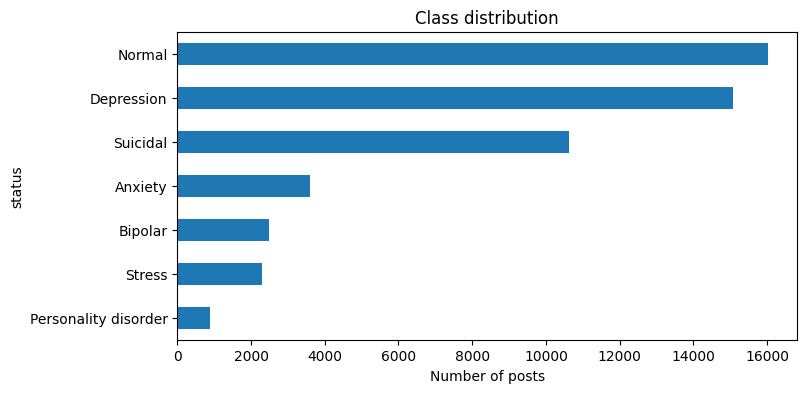

In [ ]:
counts = df["status"].value_counts()
print((counts / len(df) * 100).round(1))
print(f"Imbalance ratio: {counts.max() / counts.min():.1f}x")

counts.sort_values().plot.barh(figsize=(8, 4), title="Class distribution")
plt.xlabel("Number of posts")
plt.show()

                        count   mean    std  min    50%    90%    95%     max
status                                                                       
Anxiety                3611.0  143.0  152.0  1.0  102.0  315.0  424.0  1592.0
Bipolar                2501.0  178.0  181.0  4.0  130.0  366.0  483.0  4804.0
Depression            15073.0  168.0  188.0  1.0  113.0  362.0  493.0  4239.0
Normal                16018.0   17.0   23.0  1.0   10.0   35.0   72.0   255.0
Personality disorder    895.0  178.0  233.0  5.0  133.0  350.0  459.0  5419.0
Stress                 2291.0  111.0  101.0  3.0   86.0  195.0  273.0  1606.0
Suicidal              10633.0  146.0  187.0  2.0   92.0  331.0  454.0  6300.0


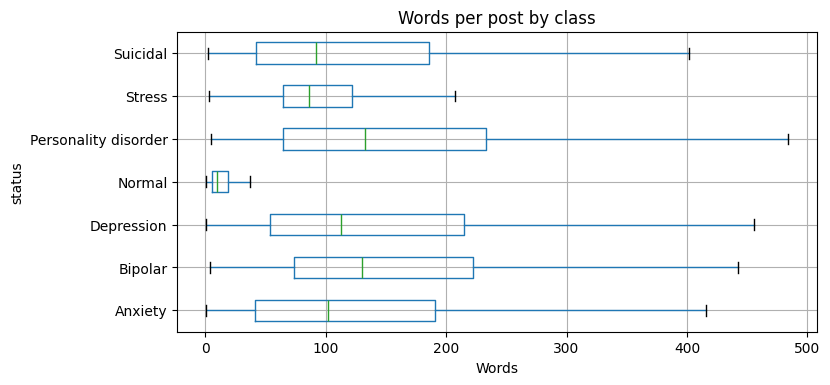

In [ ]:
df["n_words"] = df["statement"].str.split().str.len()
print(df.groupby("status")["n_words"].describe(percentiles=[.5, .9, .95]).round(0))

df.boxplot(column="n_words", by="status", vert=False, showfliers=False, figsize=(8, 4))
plt.suptitle("")
plt.title("Words per post by class")
plt.xlabel("Words")
plt.show()

In [ ]:
pd.set_option("display.max_colwidth", 300)

short = df[df["n_words"].between(8, 40)]
short.groupby("status").sample(1, random_state=42)[["status", "statement"]]

,status,statement
480,Anxiety,"So often restless in the middle of the night but for no reason, why is this"
45842,Bipolar,Geodon users? Just started taking Geodon and am not enjoying how cloudy I feel. Does it get better?
13195,Depression,"i took a shower last night and shaved my legs for the first time in 5-6 months, i feel very proud :) i took care of myself yay"
32991,Normal,i was there when i was a kid.
50813,Personality disorder,"one interaction ruins the whole day If I interact with 5 people a day, 4 turn out to be ok, and the other 1 will destroy my whole mood. is it not better not to interact with all 5?"
30012,Stress,You’re losing control Juststopthinking— —You’re panicking Stop —Panicking
17418,Suicidal,"If a man has no purpose, his life is just a continuous death i have no purpose so what is the point"


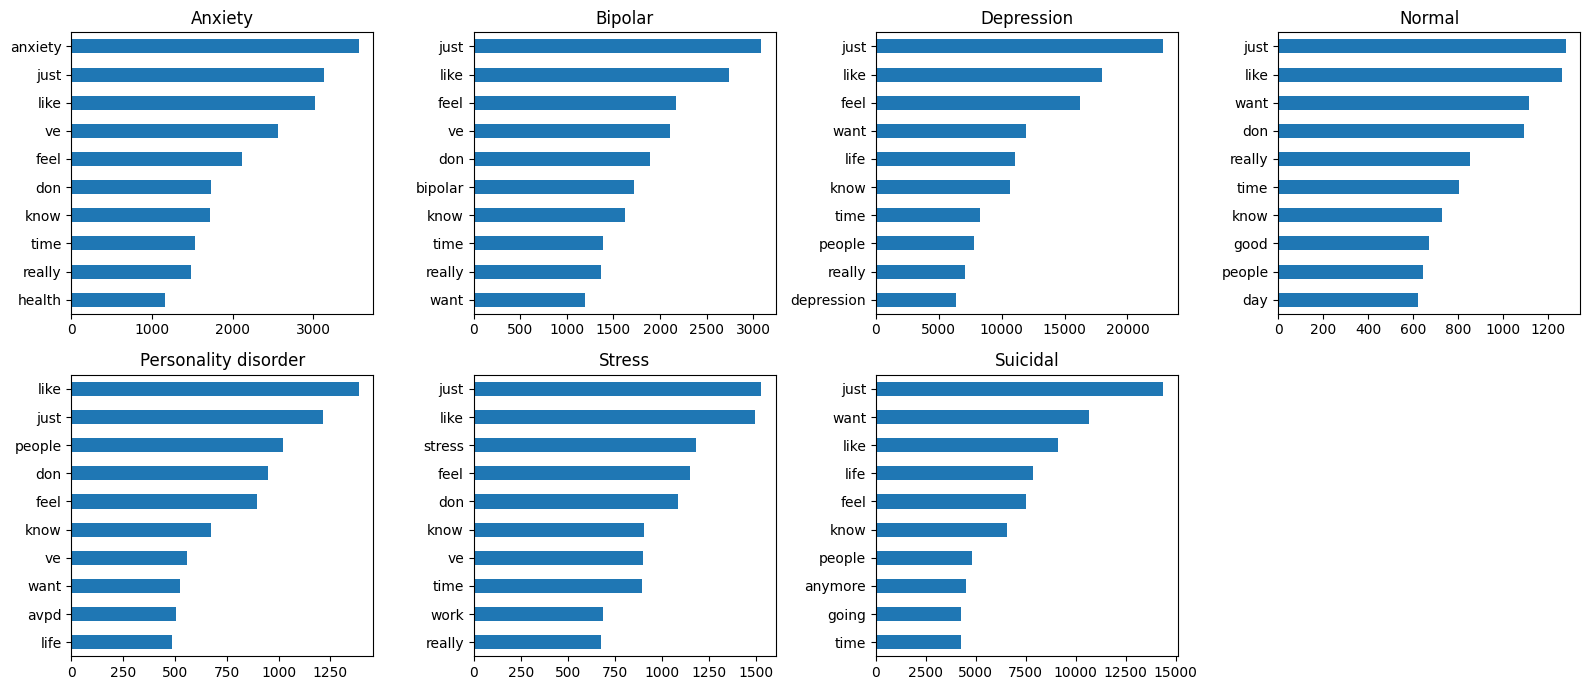

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, cls in zip(axes.ravel(), sorted(df["status"].unique())):
    cv = CountVectorizer(stop_words="english", max_features=10)
    X = cv.fit_transform(df.loc[df["status"] == cls, "statement"])
    freq = pd.Series(X.sum(axis=0).A1, index=cv.get_feature_names_out()).sort_values()
    freq.plot.barh(ax=ax, title=cls)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

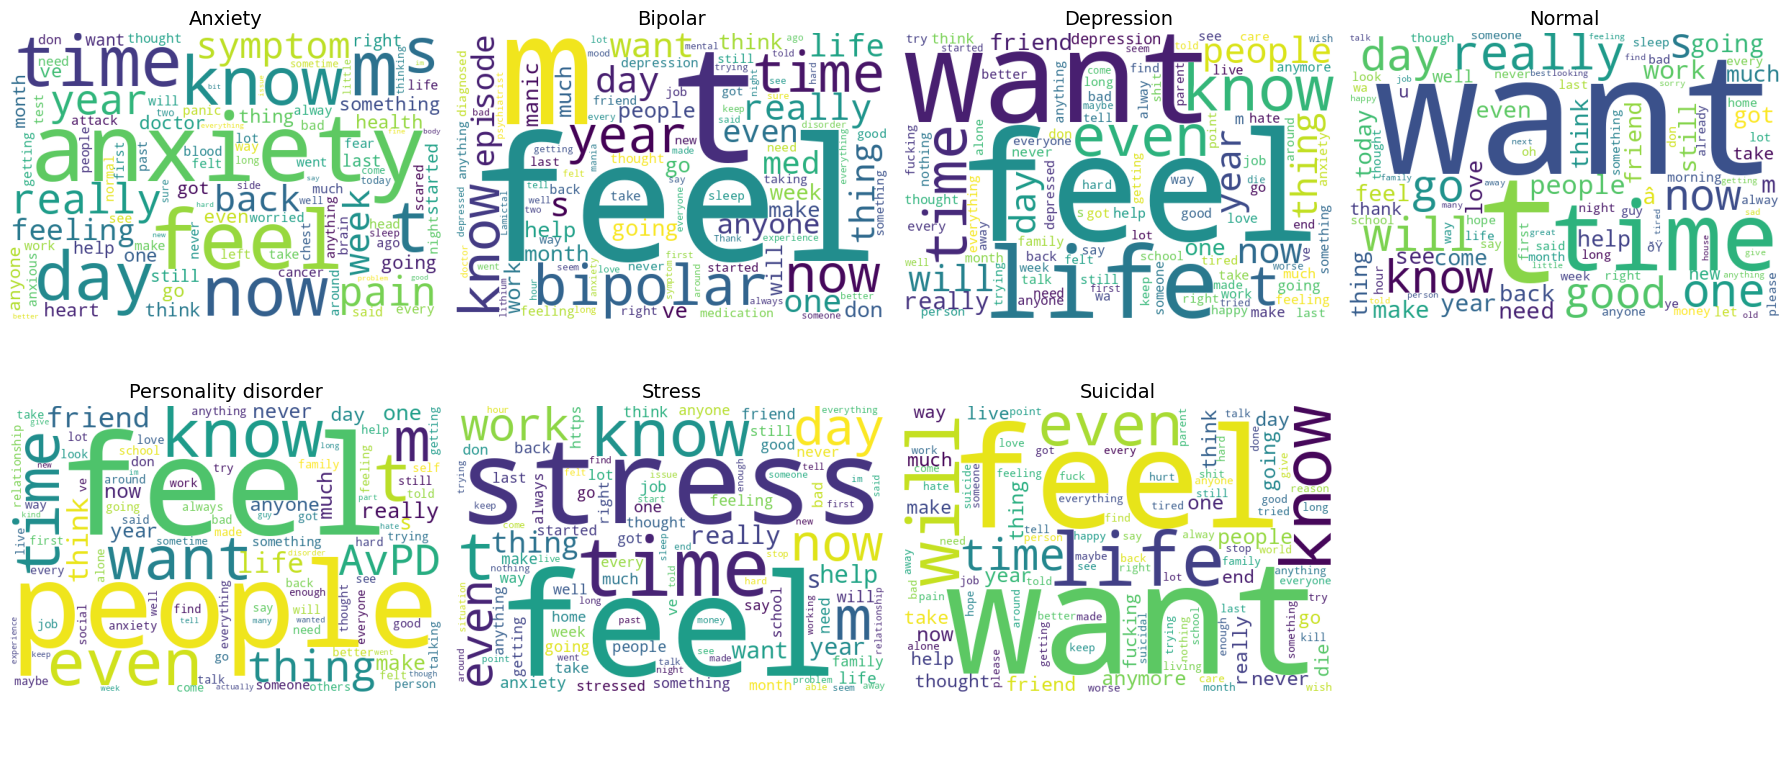

In [ ]:
stopwords = STOPWORDS

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, cls in zip(axes.ravel(), sorted(df["status"].unique())):
    text = " ".join(df.loc[df["status"] == cls, "statement"])
    wc = WordCloud(width=600, height=400, background_color="white",
                   stopwords=stopwords, max_words=100, collocations=False).generate(text)
    ax.imshow(wc)
    ax.set_title(cls, fontsize=14)
    ax.axis("off")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
df = df.drop(columns="n_words")

train, temp = train_test_split(df, test_size=0.3, stratify=df["status"], random_state=42)
val, test = train_test_split(temp, test_size=0.5, stratify=temp["status"], random_state=42)

train.to_csv(f"{SPLIT_DIR}/train.csv", index=False)
val.to_csv(f"{SPLIT_DIR}/val.csv", index=False)
test.to_csv(f"{SPLIT_DIR}/test.csv", index=False)
print(len(train), len(val), len(test))

35715 7653 7654


In [ ]:
proportions = pd.DataFrame({
    "full":  df["status"].value_counts(normalize=True),
    "train": train["status"].value_counts(normalize=True),
    "val":   val["status"].value_counts(normalize=True),
    "test":  test["status"].value_counts(normalize=True),
}).mul(100).round(2)

proportions["count (train/val/test)"] = [
    f"{(train.status == c).sum()} / {(val.status == c).sum()} / {(test.status == c).sum()}"
    for c in proportions.index
]
proportions

,full,train,val,test,count (train/val/test)
status,,,,,
Normal,31.39,31.39,31.40,31.40,11212 / 2403 / 2403
Depression,29.54,29.54,29.54,29.54,10551 / 2261 / 2261
Suicidal,20.84,20.84,20.84,20.84,7443 / 1595 / 1595
Anxiety,7.08,7.08,7.07,7.08,2528 / 541 / 542
Bipolar,4.90,4.90,4.90,4.90,1751 / 375 / 375
Stress,4.49,4.49,4.48,4.49,1604 / 343 / 344
Personality disorder,1.75,1.75,1.76,1.75,626 / 135 / 134
